     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 126.2 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Device: cuda


100%|██████████| 2.64G/2.64G [03:12<00:00, 13.7MB/s]


Saved STL10 images to /content/attribution_project/data/images
Created synthetic training set at /content/attribution_project/data/synth_train total images: 3000
Created synthetic test set at /content/attribution_project/data/synth_test total images: 1000
Classes: ['copy_move', 'gan_regen', 'mobile_filter', 'original', 'photoshop']
Train size: 3000 Test size: 1000


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 135MB/s]


... (12 outputs left out)

  0%|          | 0/94 [00:00<?, ?it/s]

Epoch 7 loss 0.0370 acc 0.9903


  0%|          | 0/94 [00:00<?, ?it/s]

Epoch 8 loss 0.0365 acc 0.9900
               precision    recall  f1-score   support

    copy_move       0.95      0.86      0.91       200
    gan_regen       1.00      0.99      1.00       200
mobile_filter       0.98      0.96      0.97       200
     original       0.86      0.91      0.88       200
    photoshop       0.95      1.00      0.97       200

     accuracy                           0.95      1000
    macro avg       0.95      0.95      0.95      1000
 weighted avg       0.95      0.95      0.95      1000

Confusion matrix:
 [[173   0   0  23   4]
 [  0 199   1   0   0]
 [  0   0 193   7   0]
 [  9   0   2 182   7]
 [  0   0   0   0 200]]


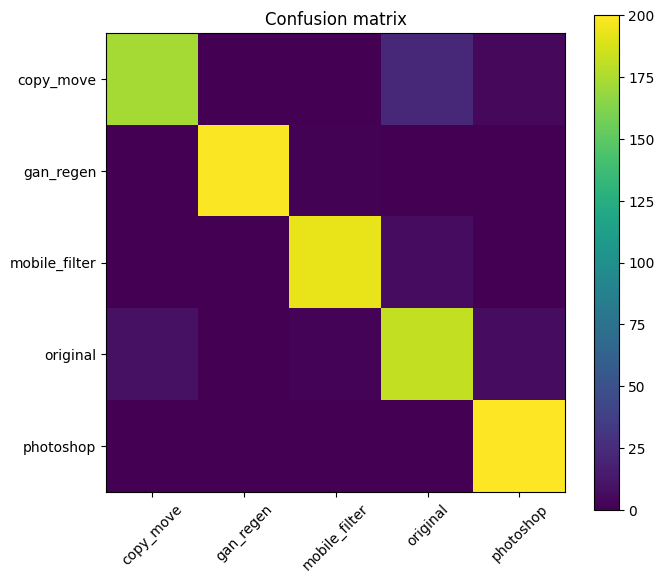

Saved: /content/gradcam_results/gradcam_137.png
Saved: /content/gradcam_results/gradcam_147.png
Saved: /content/gradcam_results/gradcam_725.png
Saved: /content/gradcam_results/gradcam_336.png
Saved: /content/gradcam_results/gradcam_364.png
Saved: /content/gradcam_results/gradcam_43.png
Saved: /content/gradcam_results/gradcam_353.png
Saved: /content/gradcam_results/gradcam_315.png
Saved: /content/gradcam_results/gradcam_996.png
Saved: /content/gradcam_results/gradcam_61.png


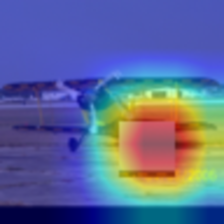

Saved final model to /content/attribution_project/final_model.pth


In [ ]:
# -----------------------------
# Cell 1 — install required libs
# -----------------------------
!pip install -q torch torchvision timm scikit-image matplotlib tqdm opencv-python pillow grad-cam sentence-transformers

# -----------------------------
# Cell 2 — imports & config
# -----------------------------
import os, random, time, io
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import torchvision
from PIL import Image, ImageFilter, ImageEnhance, ImageOps, ImageDraw
import cv2

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print("Device:", DEVICE)

ROOT = '/content/attribution_project'
os.makedirs(ROOT, exist_ok=True)
DATA_DIR = os.path.join(ROOT, 'data')
os.makedirs(DATA_DIR, exist_ok=True)

# -----------------------------
# Cell 3 — download / prepare dataset (STL10 higher res)
# -----------------------------
from torchvision.datasets import STL10

DATA_ROOT = os.path.join(DATA_DIR, 'stl10')
train_set = STL10(DATA_ROOT, split='train', download=True)
test_set  = STL10(DATA_ROOT, split='test',  download=True)

# Save images into simple folders for pipeline processing
IMG_DIR = os.path.join(DATA_DIR, 'images')
os.makedirs(IMG_DIR, exist_ok=True)

def save_subset(dataset, out_dir, prefix='img'):
    os.makedirs(out_dir, exist_ok=True)
    for i in range(len(dataset)):
        img, label = dataset[i]
        if isinstance(img, torch.Tensor):
            # convert tensor to PIL
            img = T.ToPILImage()(img)
        img.save(os.path.join(out_dir, f"{prefix}_{i}.png"))

save_subset(train_set, os.path.join(IMG_DIR, 'train'), prefix='img')
save_subset(test_set, os.path.join(IMG_DIR, 'test'), prefix='img')

print("Saved STL10 images to", IMG_DIR)

# -----------------------------
# Cell 4 — editing pipeline functions
# -----------------------------
def pipeline_original(img: Image.Image):
    return img

def pipeline_mobile_filter(img: Image.Image):
    img2 = ImageEnhance.Color(img).enhance(1.25)
    img2 = ImageEnhance.Contrast(img2).enhance(1.15)
    img2 = img2.filter(ImageFilter.GaussianBlur(radius=0.6))
    return img2

def pipeline_photoshop_like(img: Image.Image):
    img2 = img.filter(ImageFilter.UnsharpMask(radius=1.0, percent=150, threshold=3))
    enhancer = ImageEnhance.Brightness(img2).enhance(1.03)
    w,h = enhancer.size
    mask = Image.new('L', (w,h), 0)
    draw = ImageDraw.Draw(mask)
    draw.ellipse((w*0.05,h*0.05,w*0.95,h*0.95), fill=50)
    dark = Image.new('RGB', (w,h), (30,30,30))
    enhancer.paste(dark, (0,0), mask)
    return enhancer

def pipeline_copy_move(img: Image.Image):
    img2 = img.copy()
    w,h = img.size
    size = int(min(w,h) * 0.25)
    if size < 8:
        return img2
    x = random.randint(0, w-size)
    y = random.randint(0, h-size)
    patch = img.crop((x,y,x+size,y+size)).transpose(Image.FLIP_LEFT_RIGHT)
    px = random.randint(0, w-size)
    py = random.randint(0, h-size)
    img2.paste(patch, (px,py))
    return img2

def pipeline_gan_regen(img: Image.Image):
    buf = io.BytesIO()
    img.save(buf, format='JPEG', quality=40)
    buf.seek(0)
    img2 = Image.open(buf).convert('RGB')
    img2 = ImageEnhance.Color(img2).enhance(0.9)
    img2 = img2.filter(ImageFilter.MedianFilter(size=3))
    return img2

PIPELINES = {
    'original': pipeline_original,
    'mobile_filter': pipeline_mobile_filter,
    'photoshop': pipeline_photoshop_like,
    'copy_move': pipeline_copy_move,
    'gan_regen': pipeline_gan_regen
}

# -----------------------------
# Cell 5 — Build synthesized datasets (train & test)
# -----------------------------
# synth_train
SRC_DIR = os.path.join(IMG_DIR, 'train')
OUT_DIR = os.path.join(DATA_DIR, 'synth_train')
os.makedirs(OUT_DIR, exist_ok=True)
filenames = list(Path(SRC_DIR).glob("*.png"))
n_per_pipeline = 600   # tune this per resource limits
count = 0
for name, func in PIPELINES.items():
    out_sub = os.path.join(OUT_DIR, name)
    os.makedirs(out_sub, exist_ok=True)
    for i in range(n_per_pipeline):
        src = filenames[i % len(filenames)]
        img = Image.open(src).convert('RGB')
        img_e = func(img)
        img_e.save(os.path.join(out_sub, f"{name}_{i}.png"))
        count += 1
print("Created synthetic training set at", OUT_DIR, "total images:", count)

# synth_test (separate, smaller)
SRC_DIR = os.path.join(IMG_DIR, 'test')
OUT_DIR = os.path.join(DATA_DIR, 'synth_test')
os.makedirs(OUT_DIR, exist_ok=True)
filenames = list(Path(SRC_DIR).glob("*.png"))
n_per_pipeline = 200
count = 0
for name, func in PIPELINES.items():
    out_sub = os.path.join(OUT_DIR, name)
    os.makedirs(out_sub, exist_ok=True)
    for i in range(n_per_pipeline):
        src = filenames[i % len(filenames)]
        img = Image.open(src).convert('RGB')
        img_e = func(img)
        img_e.save(os.path.join(out_sub, f"{name}_{i}.png"))
        count += 1
print("Created synthetic test set at", OUT_DIR, "total images:", count)

# -----------------------------
# Cell 6 — PyTorch Dataset & DataLoader (num_workers=0)
# -----------------------------
class EditedDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.samples = []
        self.classes = sorted([p.name for p in Path(root_dir).iterdir() if p.is_dir()])
        self.class_to_idx = {c:i for i,c in enumerate(self.classes)}
        for c in self.classes:
            for p in Path(root_dir, c).glob("*.png"):
                self.samples.append((str(p), self.class_to_idx[c]))
        self.transform = transform if transform is not None else T.Compose([
            T.Resize((224,224)),   # use 224 for ResNet pretrained default
            T.ToTensor(),
        ])
    def __len__(self): return len(self.samples)
    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = Image.open(path).convert('RGB')
        return self.transform(img), label

train_ds = EditedDataset(os.path.join(DATA_DIR,'synth_train'), transform=T.Compose([T.Resize((224,224)), T.ToTensor()]))
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=0)
test_ds  = EditedDataset(os.path.join(DATA_DIR,'synth_test'), transform=T.Compose([T.Resize((224,224)), T.ToTensor()]))
test_loader  = DataLoader(test_ds, batch_size=64, shuffle=False, num_workers=0)
print("Classes:", train_ds.classes)
print("Train size:", len(train_ds), "Test size:", len(test_ds))

# -----------------------------
# Cell 7 — Model (ResNet-18 baseline)
# -----------------------------
num_classes = len(train_ds.classes)
model = torchvision.models.resnet18(pretrained=True)
model.fc = nn.Linear(model.fc.in_features, num_classes)
model = model.to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4, weight_decay=1e-5)

# -----------------------------
# Cell 8 — Training loop
# -----------------------------
from tqdm.auto import tqdm
def train_one_epoch(model, loader, opt, criterion, device):
    model.train()
    total_loss = 0.0
    total = 0
    correct = 0
    for x,y in tqdm(loader):
        x = x.to(device); y = y.to(device)
        logits = model(x)
        loss = criterion(logits, y)
        opt.zero_grad()
        loss.backward()
        opt.step()
        total_loss += loss.item()*x.size(0)
        total += x.size(0)
        preds = logits.argmax(dim=1)
        correct += (preds==y).sum().item()
    return total_loss/total, correct/total

# Train for small number of epochs (adjust as needed)
for epoch in range(8):
    loss, acc = train_one_epoch(model, train_loader, optimizer, criterion, DEVICE)
    print(f"Epoch {epoch+1} loss {loss:.4f} acc {acc:.4f}")
    torch.save(model.state_dict(), os.path.join(ROOT, f"resnet_epoch{epoch+1}.pth"))

# -----------------------------
# Cell 9 — Evaluation & Confusion Matrix
# -----------------------------
from sklearn.metrics import confusion_matrix, classification_report
model.eval()
all_preds=[]
all_labels=[]
with torch.no_grad():
    for x,y in test_loader:
        x = x.to(DEVICE)
        logits = model(x)
        preds = logits.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds.tolist())
        all_labels.extend(y.numpy().tolist())

print(classification_report(all_labels, all_preds, target_names=test_ds.classes))
cm = confusion_matrix(all_labels, all_preds)
print("Confusion matrix:\n", cm)

plt.figure(figsize=(7,6))
plt.imshow(cm, interpolation='nearest')
plt.title('Confusion matrix')
plt.colorbar()
plt.xticks(range(len(test_ds.classes)), test_ds.classes, rotation=45)
plt.yticks(range(len(test_ds.classes)), test_ds.classes)
plt.tight_layout()
plt.show()

# -----------------------------
# Cell 10 — Improved Grad-CAM loop (save 10 images)
# -----------------------------
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

target_layer = model.layer4[-1]
cam = GradCAM(model=model, target_layers=[target_layer])

save_dir = "/content/gradcam_results"
os.makedirs(save_dir, exist_ok=True)

num_to_save = 10
indices = np.random.choice(len(test_ds), size=num_to_save, replace=False)

for idx in indices:
    img_t, label = test_ds[idx]
    input_tensor = img_t.unsqueeze(0).to(DEVICE)
    grayscale_cam = cam(input_tensor=input_tensor)[0, :]

    # convert tensor -> rgb numpy
    rgb = img_t.permute(1,2,0).cpu().numpy()
    rgb = (rgb - rgb.min()) / (rgb.max() - rgb.min())

    # resize heatmap to image size (already 224x224 here)
    heatmap = cv2.resize(grayscale_cam, (rgb.shape[1], rgb.shape[0]))

    # overlay
    visualization = show_cam_on_image(rgb.astype(np.float32), heatmap, use_rgb=True)

    # smooth & save
    visualization = cv2.GaussianBlur(visualization, (3,3), 0)
    fname = os.path.join(save_dir, f"gradcam_{idx}.png")
    cv2.imwrite(fname, cv2.cvtColor(visualization, cv2.COLOR_RGB2BGR))
    print("Saved:", fname)

# Quick display sample
from IPython.display import display, Image as IPyImage
display(IPyImage(os.path.join(save_dir, os.listdir(save_dir)[0])))

# -----------------------------
# Cell 11 — Optional multimodal (if you want)
# -----------------------------
# (Same as before; include if you have captions)
# -----------------------------
# Cell 12 — Save final model
torch.save({
    'model_state': model.state_dict(),
    'classes': train_ds.classes
}, os.path.join(ROOT, 'final_model.pth'))
print("Saved final model to", os.path.join(ROOT, 'final_model.pth'))


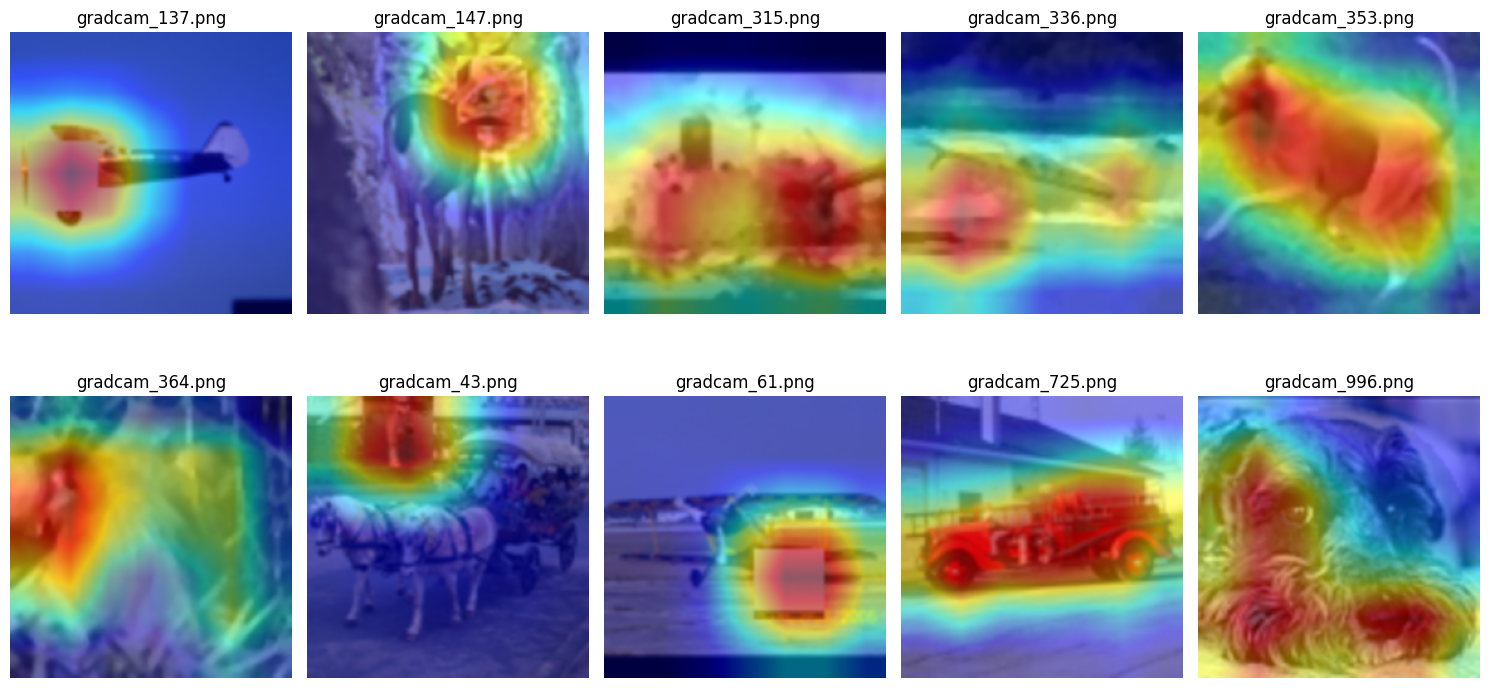

In [ ]:
# Show all Grad-CAM results in a grid
import glob
from PIL import Image
files = sorted(glob.glob("/content/gradcam_results/*.png"))
plt.figure(figsize=(15, 8))
for i, f in enumerate(files):
    img = np.array(Image.open(f))
    plt.subplot(2, 5, i+1)
    plt.imshow(img)
    plt.title(os.path.basename(f))
    plt.axis('off')
plt.tight_layout()
plt.show()


In [ ]:
# --- Grad-CAM + predicted label ---
from torch.nn.functional import softmax

img, label = test_ds[idx]
input_tensor = img.unsqueeze(0).to(DEVICE)

# Get model prediction
model.eval()
with torch.no_grad():
    logits = model(input_tensor)
    probs = softmax(logits, dim=1)
    pred_idx = torch.argmax(probs, dim=1).item()
    pred_label = test_ds.classes[pred_idx]

print(f"True label: {test_ds.classes[label]} | Predicted: {pred_label}")
print(f"Class probabilities: {probs.cpu().numpy().round(3)}")

# Compute Grad-CAM heatmap
grayscale_cam = cam(input_tensor=input_tensor)[0, :]

# Convert to RGB and overlay as before...


True label: copy_move | Predicted: copy_move
Class probabilities: [[1. 0. 0. 0. 0.]]


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful

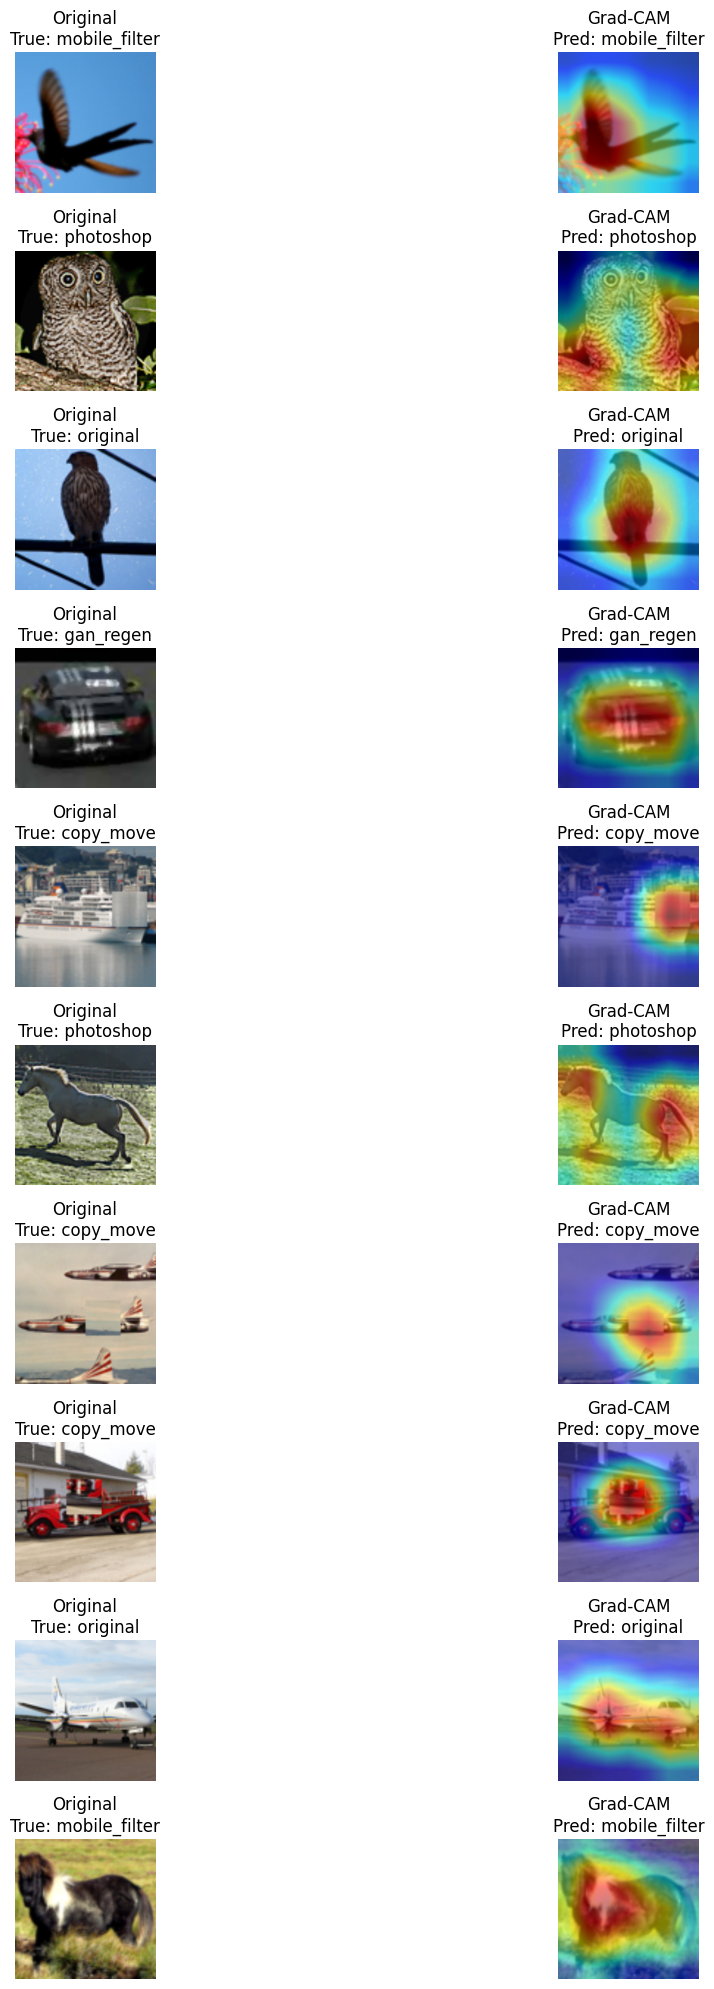

In [ ]:
# -----------------------------
# Grad-CAM + Predicted Label Visualization for Multiple Images
# -----------------------------
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from torch.nn.functional import softmax

target_layer = model.layer4[-1]
cam = GradCAM(model=model, target_layers=[target_layer])

save_dir = "/content/gradcam_results"
os.makedirs(save_dir, exist_ok=True)

num_to_show = 10  # how many examples to display
indices = np.random.choice(len(test_ds), size=num_to_show, replace=False)

plt.figure(figsize=(15, num_to_show * 2))
for i, idx in enumerate(indices, 1):
    img_t, true_label = test_ds[idx]
    input_tensor = img_t.unsqueeze(0).to(DEVICE)

    # Predict label
    model.eval()
    with torch.no_grad():
        logits = model(input_tensor)
        probs = softmax(logits, dim=1)
        pred_idx = torch.argmax(probs, dim=1).item()
        pred_label = test_ds.classes[pred_idx]

    # Grad-CAM heatmap
    grayscale_cam = cam(input_tensor=input_tensor)[0, :]
    rgb = img_t.permute(1, 2, 0).cpu().numpy()
    rgb = (rgb - rgb.min()) / (rgb.max() - rgb.min())
    heatmap = cv2.resize(grayscale_cam, (rgb.shape[1], rgb.shape[0]))
    visualization = show_cam_on_image(rgb.astype(np.float32), heatmap, use_rgb=True)
    visualization = cv2.GaussianBlur(visualization, (3, 3), 0)

    # Display Original + Grad-CAM
    plt.subplot(num_to_show, 2, 2*i - 1)
    plt.imshow(rgb)
    plt.axis('off')
    plt.title(f"Original\nTrue: {test_ds.classes[true_label]}")

    plt.subplot(num_to_show, 2, 2*i)
    plt.imshow(visualization)
    plt.axis('off')
    plt.title(f"Grad-CAM\nPred: {pred_label}")

plt.tight_layout()
plt.show()


Saving download (14).jpeg to download (14).jpeg
Predicted label: copy_move


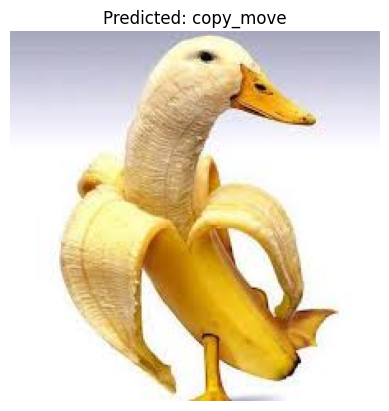

In [ ]:
# -----------------------------
# Function to upload and predict a single image
# -----------------------------
from google.colab import files
from PIL import Image
from torch.nn.functional import softmax

def predict_uploaded_image(model, classes):
    uploaded = files.upload()
    for filename in uploaded.keys():
        img = Image.open(filename).convert('RGB')
        transform = T.Compose([T.Resize((224,224)), T.ToTensor()])
        img_t = transform(img).unsqueeze(0).to(DEVICE)

        model.eval()
        with torch.no_grad():
            logits = model(img_t)
            probs = softmax(logits, dim=1)
            pred_idx = torch.argmax(probs, dim=1).item()
            pred_label = classes[pred_idx]

        print(f"Predicted label: {pred_label}")
        plt.imshow(img)
        plt.title(f"Predicted: {pred_label}")
        plt.axis('off')
        plt.show()

# Example usage:
predict_uploaded_image(model, test_ds.classes)
